# Importing Data

In [15]:
import kagglehub
import pandas as pd
import os

path = kagglehub.dataset_download("ealaxi/paysim1")
print("Dataset downloaded to:", path)

files_in_dataset = os.listdir(path)
print("Files in the dataset:", files_in_dataset)

file_path = os.path.join(path, "PS_20174392719_1491204439457_log.csv")
df = pd.read_csv(file_path)

Dataset downloaded to: C:\Users\Ева\.cache\kagglehub\datasets\ealaxi\paysim1\versions\2
Files in the dataset: ['PS_20174392719_1491204439457_log.csv']


In [16]:
print("\n --General Info-- \n", df.info(), "\n")
print(df.describe(), "\n")
print("--Data Shape-- \n ", df.shape, "\n")
print("--Data Types-- \n ", df.dtypes, "\n")

print(df.isnull().sum())
print(df['isFraud'].value_counts()) # checking the distribution of the target variable ('isFraud')

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB

 --General Info-- 
 None 

               step        amount  oldbalanceOrg  newbalanceOrig  \
count  6.362620e+06  6.362620e+06   6.362620e+06    6.362620e+06   
mean   2.433972e+02  1.798619e+05   8.338831e+05    8.551137e+05   
std    1.423320e+02  6.038582e+05   2.888243e+06    2.924049e+06   
min    1.000000e+00  0.000000e+00   0.000000e+00    0.000000e+00   
25%    1.560000e+02  1.338957e+04   0.000000e+00    0.000000e+00   
50%    2.390000e+02  7.48

# Importing Necessary Libraries

In [17]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import plotly.express as px

# Visualising Data

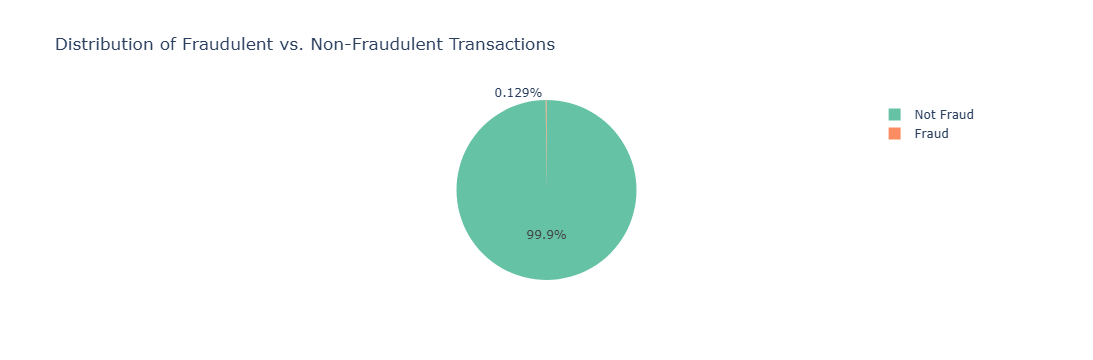

In [18]:
fraud_counts = df['isFraud'].value_counts()
fig = px.pie(values=fraud_counts.values, names=['Not Fraud', 'Fraud'], title='Distribution of Fraudulent vs. Non-Fraudulent Transactions', color_discrete_sequence=['#66c2a5', '#fc8d62'])
fig.show()

# Data Preprocessing

In [19]:
df = pd.get_dummies(df, columns=['type'], drop_first=True)
df = df.drop(['nameOrig', 'nameDest'], axis=1)
df['transaction_diff'] = df['oldbalanceOrg'] - df['newbalanceOrig']
df['recipient_diff'] = df['oldbalanceDest'] - df['newbalanceDest']
df['amount_log'] = np.log1p(df['amount'])

# Splitting Features and Targets

In [10]:
X = df.drop('isFraud', axis=1)
y = df['isFraud']

# Data Training and Testing

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Initializing and Training the Model

In [32]:
model = DecisionTreeClassifier(max_depth=5, min_samples_split=10, class_weight= 'balanced', random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fea

# Predicting and Evaluating the Model

In [35]:
y_pred = model.predict(X_test)
y_probs = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probs)
print(f"Model Accuracy: {accuracy:.4f}")
print(f"ROC-AUC Score: {roc_auc:.4f}")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9864
ROC-AUC Score: 0.9941
              precision    recall  f1-score   support

           0       1.00      0.99      0.99   1906322
           1       0.08      0.96      0.15      2464

    accuracy                           0.99   1908786
   macro avg       0.54      0.97      0.57   1908786
weighted avg       1.00      0.99      0.99   1908786



# Test on One Example

In [34]:
example = X_test.iloc[[0]]
prediction = model.predict(example)[0]
print("Prediction:", "Fraud" if prediction == 1 else "Not Fraud")
print("Actual:", "Fraud" if y_test.iloc[0] == 1 else "Not Fraud")


with open("prediction_result.txt", "w") as f:
    f.write(f"Prediction: {prediction}\nActual: {y_test.iloc[0]}\n")

Prediction: Not Fraud
Actual: Not Fraud
